### Example 2: An internal wavemaker for waves on currents

In example 1 the waves came from an initial condition, which is fine for transient wave packets. But very often we want a steady stream of incoming waves that keeps propagating over the current and bathymetry we care about. As there are no inflow boundaries in WaCuBa (the domain is periodic with sponge layers), the waves have to be made inside the domain by a source term $S(t,X)$:
$$
\begin{cases}
\partial_t \eta + \nabla_X\cdot(\bar{U}\eta) = \mathcal{G}(b)\varphi + S(t,X), \\
\partial_t \varphi + \bar{U}\cdot\nabla_X\varphi = -g\eta.
\end{cases}
$$
We now briefly describe how to construct $S$ so that it sends out the wave we want, in one direction only. Below is a quick sketch of the construction. We want the source to generate a incoming field that has a prescribed spectrum given a constant current and bathymetry. 
### The 1D problem

We start with one dimension, constant current $U$ and constant depth $H$. Eliminating $\varphi$ gives
$$ (\partial_t + U\partial_x)^2\eta + gG(H)\eta = (\partial_t + U\partial_x)S. $$
With a time-harmonic source $S = \mathrm{Re}\{s(x)e^{-i\omega t}\}$ and $\eta = \mathrm{Re}\{\zeta(x)e^{-i\omega t}\}$ the relevant wavenumbers are the real roots $k_j$ of the dispersion relation
$$ D(k,\omega) = \sigma^2(k) - (\omega - Uk)^2 = 0, \qquad \sigma^2(k) = g|k|\tanh(H|k|). $$
With a current there are typically four of them (two with no current). Working out the causal Green's function with the residue theorem, the poles are shifted above or below the real axis depending on the sign of the group velocity $C_g = \mathrm{d}\omega/\mathrm{d}k$, and the $(\omega - Uk)$ factors cancel against the right-hand side. The final expression is quite simple: away from a compactly supported source the field is a sum of plane waves,
$$ \zeta(x) = \sum_{j:\,C_g(k_j)>0} \frac{\widehat{s}(k_j)}{2C_g(k_j)}e^{ik_jx} \quad \text{(downstream of the source)}, \qquad \zeta(x) = -\sum_{j:\,C_g(k_j)<0}\frac{\widehat{s}(k_j)}{2C_g(k_j)}e^{ik_jx} \quad \text{(upstream)}, $$
where $\widehat{s}(k) = \int e^{-iky}s(y)\,\mathrm{d}y$. So each root radiates with strength $\widehat{s}(k_j)$ to the side its group velocity points to.

### Building the source

We want only the wave with wavenumber $k^*$, so we need $\widehat{s}(k_j) = 0$ at every other root and $\widehat{s}(k^*) = 2aC_g(k^*)$ to get amplitude $a$. The roots can be removed with a differential operator, since $\partial_x \to ik$ in Fourier space. Taking a smooth bump $B$ supported on $[x_c - W, x_c + W]$ and modulating it with the carrier,
$$ s(x) = \Lambda\, e^{ik^*(x - x_c)} \prod_{j}\frac{\partial_x - i(k_j - k^*)}{i(k^* - k_j)} B(x), \qquad B(x) = \exp\left(-\frac{1}{1 - ((x - x_c)/W)^2}\right), $$
gives $\widehat{s}(k) \propto \prod_j \frac{k - k_j}{k^* - k_j}\,\widehat{B}(k - k^*)$, which vanishes at all the unwanted roots and equals $\Lambda\int B$ at $k^*$. So
$$ \Lambda = \frac{2a\,|C_g(k^*)|}{\int B\,\mathrm{d}x}. $$
The bump has to be $C^\infty$, since we take up to three derivatives of it and any kink would leak energy everywhere. The derivatives are evaluated analytically.

### 2D and spectra

In 2D we just apply the 1D method by extending the the source along a line. For a wave in direction $\theta$ we use the rotated coordinate $x' = (X - X_c)\cdot(\cos\theta, \sin\theta)$, the projected current $U_\mathrm{eff} = \bar U\cdot(\cos\theta,\sin\theta)$ in the dispersion relation, and a long smooth window across the beam so the source is a finite line. Since everything is linear, a spectral wavemaker is a sum of such sources, one for each component $(k_j, \theta_j, a_j)$ with random phases, and `create_spectral_source` creates this sum.

The functions are added in `wave_module.py`:
- `create_exact_unidirectional_source(X, Y, k, U, H, center, theta, a, ...)`: one wave
- `create_spectral_source(X, Y, k, theta, a, U, H, center, ...)`: a list of components
- `create_line_source(X, Y, k, theta, a, U, H, center, y_extent, taper, ...)`: one wave or a list of components from a straight line at $x = x_c$ (see below)
- `dispersion_roots`, `group_velocity` and `wave_frequency`: the 1D dispersion bits used above

Both return a function `F(t)` which is passed to `simulate_wave_system(..., source=F)`.

## Examples

Before the verification, here is what using the wavemaker looks like. We use a flat bottom $H = 10$ m, a constant current $\bar U = (0.4, 0.15)$ m/s and sponges on all four sides.

For the examples we use `create_line_source`. Instead of rotating the source line for each direction, it keeps one straight line at $x = x_c$ and makes the tilt with the phase $e^{ik_y y}$ along the line, solving the 1D problem in $x$ with $k_y$ fixed. The ends of the line are tapered and run into the top and bottom sponges, so whatever they diffract gets absorbed. That keeps the field much cleaner than a rotated line when the waves are oblique. The sponges are about two of the longest wavelengths thick.

In [8]:
import sys
import os
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np
import matplotlib.pyplot as plt
import wave_module as wm
%load_ext autoreload
%autoreload 2
# Domain and resolution
Lx, Ly, Nx, Ny = 1000, 800, 320, 256
X, Y, dx, dy = wm.build_grid(Lx, Ly, Nx, Ny)

# Flat bottom and constant current
H = 10
U0 = (0.4, 0.15)
U = U0[0]*np.ones_like(X), U0[1]*np.ones_like(X)
topo_data = wm.precompute_dtn_system(Lx, Ly, Nx, Ny, H*np.ones_like(X), flat_bottom=True)

# Sponges on all sides, about two of the longest wavelengths (52 m) thick
sponge_frac = 0.13
sponge_sides = "lrtb"
sigma_max = 1.0

# Source line at x = 220 m, running from y = 10 to 790 m with 170 m tapers at the ends
center = (220, 400)
line = dict(y_extent=(10, 790), taper=170)

dt = 0.1

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### A monochromatic wave

One wave with wavelength 40 m, amplitude 0.5 m, heading $20°$ from the $x$-axis.

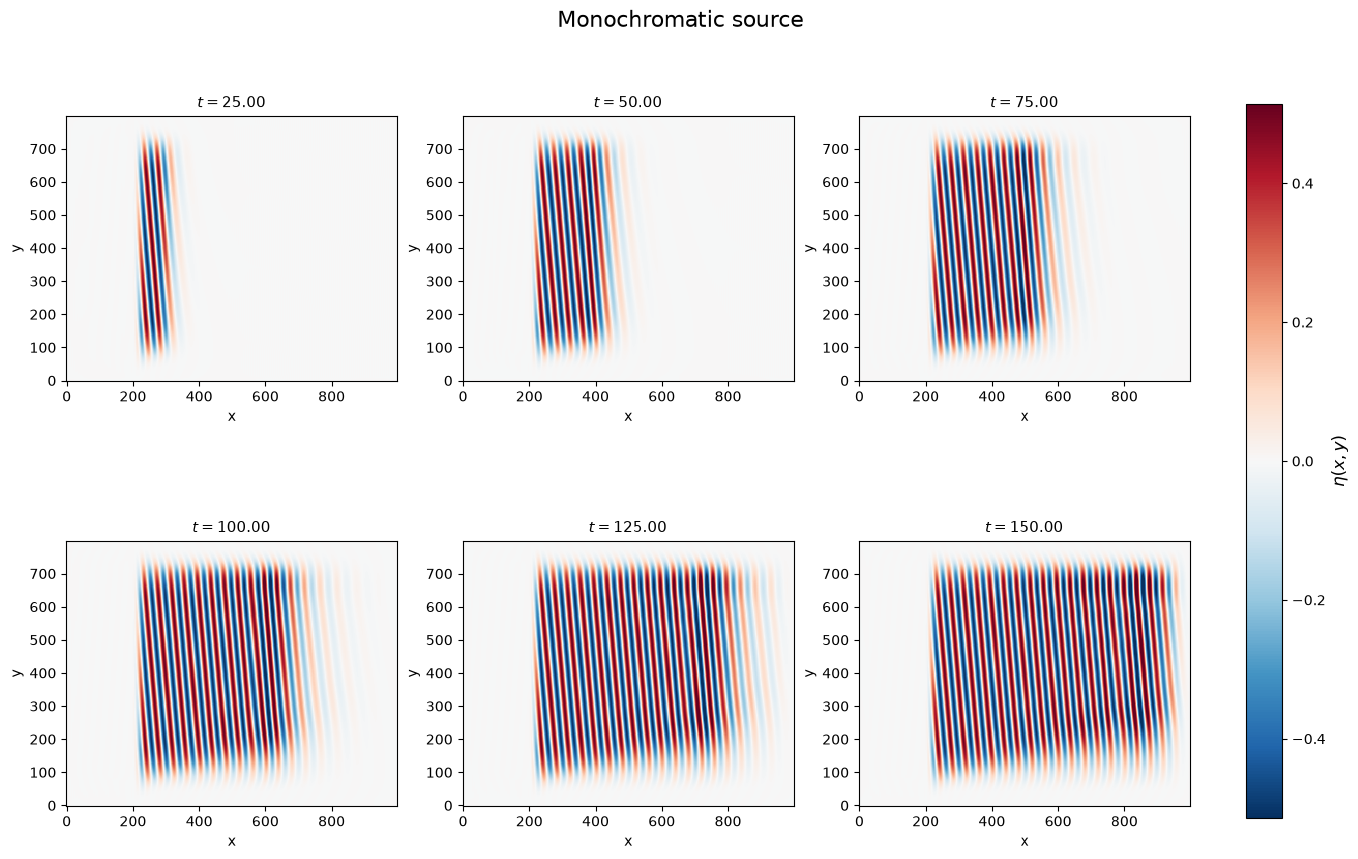

In [9]:
F_mono = wm.create_line_source(X, Y, 2*np.pi/40, np.deg2rad(5), 0.5, U0, H, center, **line)

t_snaps, eta_snaps, phi_snaps, energy_density_snaps = wm.simulate_wave_system(
    Lx, Ly, Nx, Ny,
    150, dt,
    np.zeros_like(X), np.zeros_like(X),
    U,
    topo_data,
    sponge_frac=sponge_frac,
    sponge_sides=sponge_sides,
    sigma_max=sigma_max,
    snapshot_interval=25,
    source=F_mono,
)

wm.wave_plots(eta_snaps[1:], 6, X, Y, Lx, Ly, t_list=t_snaps[1:], title="Monochromatic source", cmap="RdBu_r")

### A directional spectrum

We use the following incoming spectrum: 5 wavenumbers between 0.12 and 0.20 rad/m times 5 directions between $-6°$ and $6°$, with a Gaussian shape in $k$, $\cos^4\theta$ spreading and random phases. The same function takes arrays of $(k_j, \theta_j, a_j)$.

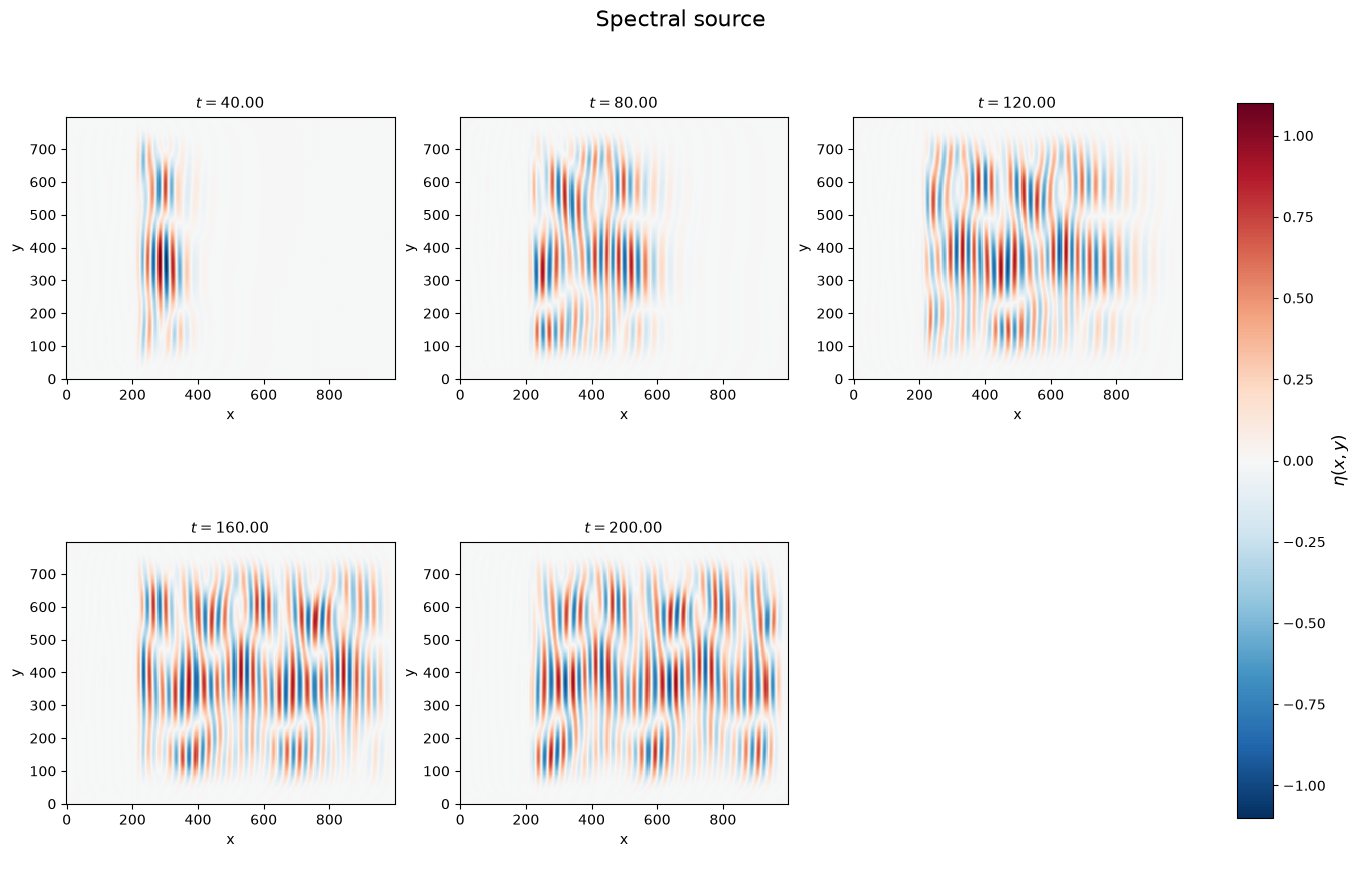

In [ ]:
KK, TT = np.meshgrid([0.12, 0.14, 0.16, 0.18, 0.20], np.deg2rad([-6, -3, 0, 3, 6]))
AA = np.exp(-0.5*((KK - 0.16)/0.03)**2)*np.cos(TT)**4
AA *= 0.5/np.sqrt(np.sum(AA**2))      # Hs = 4 sqrt(sum a^2/2) = 1.4 m

F_spec = wm.create_line_source(X, Y, KK.ravel(), TT.ravel(), AA.ravel(), U0, H, center,
                               ramp_periods=5, seed=1, **line)

t_snaps, eta_snaps, phi_snaps, energy_density_snaps = wm.simulate_wave_system(
    Lx, Ly, Nx, Ny,
    200, dt,
    np.zeros_like(X), np.zeros_like(X),
    U,
    topo_data,
    sponge_frac=sponge_frac,
    sponge_sides=sponge_sides,
    sigma_max=sigma_max,
    snapshot_interval=40,
    source=F_spec,
)
wm.wave_plots(eta_snaps[1:], 6, X, Y, Lx, Ly, t_list=t_snaps[1:], title="Spectral source", cmap="RdBu_r")

### A directional spectrum over a bump and variable current

We keep the same spectrum and add a bump in the bathymetry and a eddy-like current.  Let $b(X) = 20 - 10\exp(-(x-(3L_x/4))^2 - (y - L_y/2)^2 )$ and $U = 

System Setup: 320x256 grid. Active modes: 2548 (3.1%). Mean depth h=19.21.
Matrix Condition Number: 6.33e+01


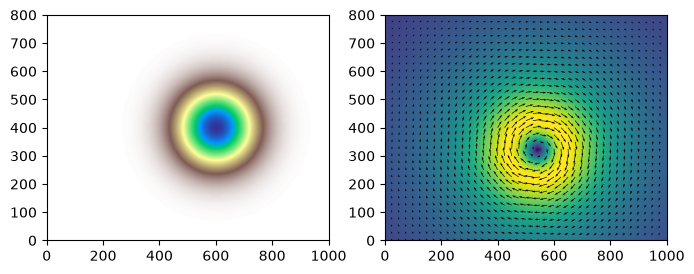

In [37]:
#bathymetry
X_c = 3*Lx/5
Y_c = Ly/2
sigma_x = Lx/10
sigma_y = Ly/8
b = 20 - 10*np.exp(-((X-X_c)**2/(2*sigma_x**2) + (Y-Y_c)**2/(2*sigma_y**2)))

#current 
X_uc = 0.9*X_c
Y_uc = 0.8*Y_c
sigma_u = Lx/15
R = np.sqrt((X - X_uc+1e-10)**2 + (Y - Y_uc+1e-10)**2)
U1 = (8*sigma_u/(2*np.pi))*(1-np.exp(-R**2/(2*sigma_u**2)))*(Y - Y_uc)/R**2 
U2 = -(8*sigma_u/(2*np.pi))*(1-np.exp(-R**2/(2*sigma_u**2)))*(X - X_uc)/R**2

U = U1, U2
topo_data = wm.precompute_dtn_system(Lx, Ly, Nx, Ny, b, k_cutoff=0.2, flat_bottom=False)

fig, ax = plt.subplots(1,2,figsize=(8, 16))
ax[0].imshow(b, extent=(0, Lx, 0, Ly), origin="lower", cmap="terrain")
ax[1].imshow(np.sqrt(U[0]**2 + U[1]**2), extent=(0, Lx, 0, Ly), origin="lower", cmap="viridis")
ax[1].quiver(X[::8, ::8], Y[::8, ::8], U[0][::8, ::8], U[1][::8, ::8], color="k")

plt.show()



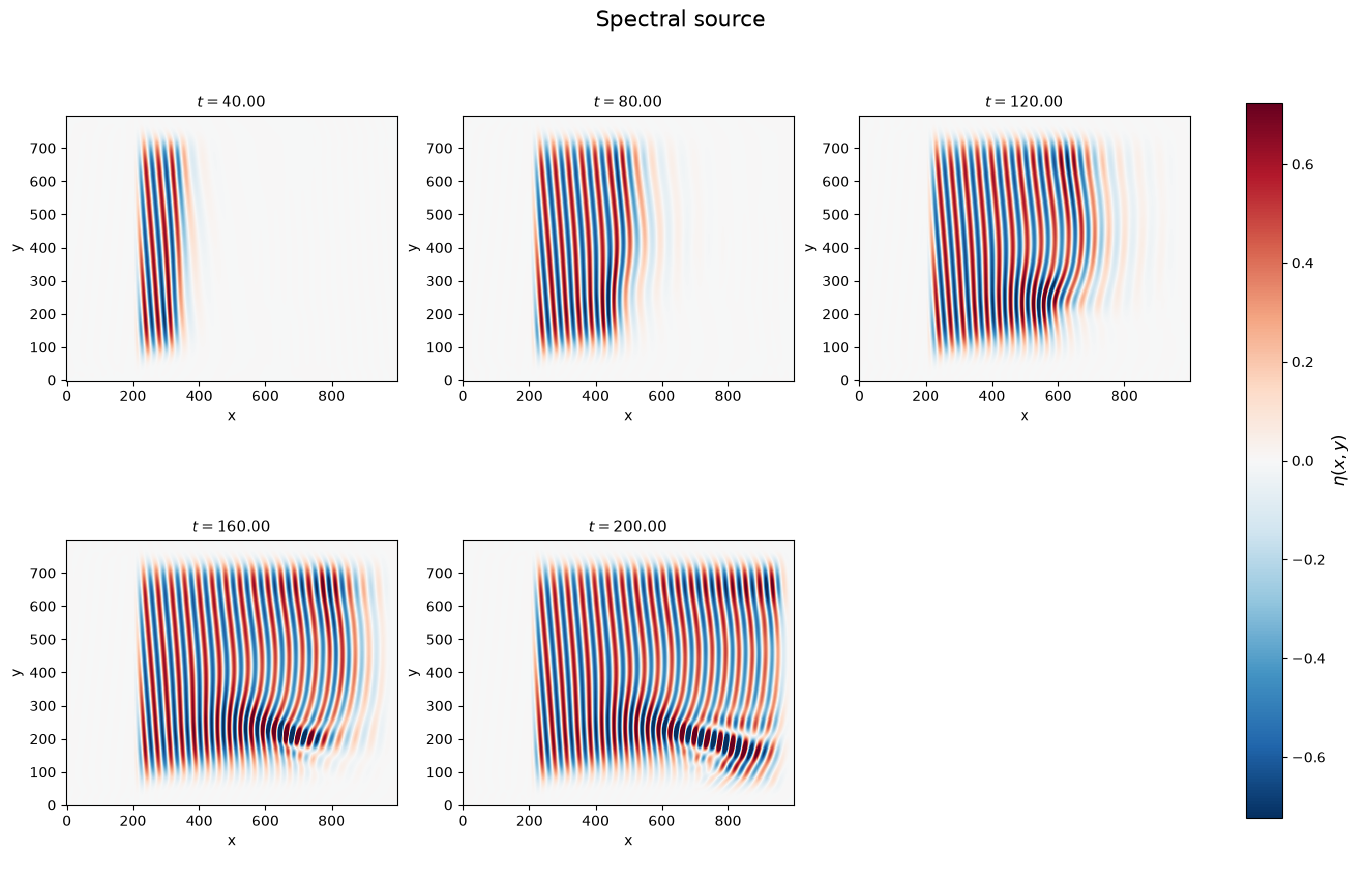

In [38]:
t_snaps, eta_snaps, phi_snaps, energy_density_snaps = wm.simulate_wave_system(
    Lx, Ly, Nx, Ny,
    200, dt,
    np.zeros_like(X), np.zeros_like(X),
    U,
    topo_data,
    sponge_frac=sponge_frac,
    sponge_sides=sponge_sides,
    sigma_max=sigma_max,
    snapshot_interval=40,
    source=F_mono,
)
wm.wave_plots(eta_snaps[1:], 6, X, Y, Lx, Ly, t_list=t_snaps[1:], title="Spectral source", cmap="RdBu_r")

## Verification

### Setup

We now want to verify that the propagated field has presribed properties. We take a flat bottom  $H = 10$ m and a constant current $\bar U = (0.4, 0.15)$ m/s. The source sits at $X_c = (220, 400)$ m and we record $\eta$ in a $200 \times 160$ m box about 130 to 330 m downstream of it, away from the sponges and the edges of the beam.

**How we measure the spectrum.** After the waves have filled the box we store $\eta$ there every 0.5 s for a while. From that record we compute
- the frequency spectrum: FFT in time (Hann window), averaged over all points in the box,
- the wavenumber spectrum: FFT in space (2D Hann window), averaged over time. We use the analytic signal in time so a wave going one way doesn't also show up at $-\mathbf{k}$.

To compare with the input we evaluate the input wave field $\sum_j a_j\cos(\mathbf{k}_j\cdot(X - X_c) - \omega_j t + \phi_j)$ on the same box and times and push it through exactly the same steps. That way the windowing and resolution are the same for both, and any difference is down to the wavemaker.

In [6]:

sys.path.append(os.path.abspath('../src'))
from scipy.signal import hilbert


Lx, Ly, Nx, Ny = 1000, 800, 320, 256
X, Y, dx, dy = wm.build_grid(Lx, Ly, Nx, Ny)
H = 10
U0 = (0.4, 0.15)
U = U0[0]*np.ones_like(X), U0[1]*np.ones_like(X)
topo_data = wm.precompute_dtn_system(Lx, Ly, Nx, Ny, H*np.ones_like(X), flat_bottom=True)

dt = 0.1
sponge = dict(sponge_frac=0.05, sponge_sides="lrtb", sigma_max=1.0)   # two of the longest wavelengths
center = (220, 400)
source_geometry = dict(width=60, length=780, taper=150)    # along the beam, across it, end tapers

box = (slice(103, 154), slice(113, 176))                 # x in [353, 547], y in [322, 478]
Xb, Yb = X[box], Y[box]


def run(F, T_final, t_record, sponge=sponge):
    # run with source F and return the times and eta in the box after t_record
    rec_t, rec_eta = [], []
    def callback(t, eta, phi):
        if t > t_record and round(t/dt) % 5 == 0:
            rec_t.append(t)
            rec_eta.append(eta[box].copy())
    _, eta_snaps, _, _ = wm.simulate_wave_system(Lx, Ly, Nx, Ny, T_final, dt, 0*X, 0*X, U, topo_data,
                                                 source=F, callback=callback, **sponge)
    return np.array(rec_t), np.array(rec_eta), eta_snaps[-1]


def input_field(t, k, theta, a, omega, phase):
    # the wave field we asked for, on the box
    kx, ky = k*np.cos(theta), k*np.sin(theta)
    arg = (kx[:, None, None]*(Xb - center[0]) + ky[:, None, None]*(Yb - center[1]))[None] \
          - omega[None, :, None, None]*t[:, None, None, None] + phase[None, :, None, None]
    return np.sum(a[None, :, None, None]*np.cos(arg), axis=1)


def spectra(t, eta, pad=4):
    # frequency spectrum (averaged over the box) and wavenumber spectrum (averaged over time),
    # both normalised to sum to the variance of eta
    nt, ny, nx = eta.shape
    wt = np.hanning(nt)[:, None, None]
    Pw = np.mean(np.abs(np.fft.rfft(eta*wt, axis=0))**2, axis=(1, 2))/(np.sum(wt**2)*nt)
    Pw[1:] *= 2
    omega = 2*np.pi*np.fft.rfftfreq(nt, t[1] - t[0])

    eta_a = np.conj(hilbert(eta, axis=0))[nt//10:-nt//10]   # analytic signal, ends dropped
    w = np.outer(np.hanning(ny), np.hanning(nx))
    Pk = np.mean(np.abs(np.fft.fft2(eta_a*w, s=(pad*ny, pad*nx)))**2, axis=0)/(2*np.sum(w**2)*pad**2*nx*ny)
    kx = np.fft.fftshift(2*np.pi*np.fft.fftfreq(pad*nx, dx))
    ky = np.fft.fftshift(2*np.pi*np.fft.fftfreq(pad*ny, dy))
    return omega, Pw, kx, ky, np.fft.fftshift(Pk)


def compare(t, eta_sim, eta_in, eta_final, k, theta, klim, wlim):
    om, Pw_sim, kx, ky, Pk_sim = spectra(t, eta_sim)
    _, Pw_in, _, _, Pk_in = spectra(t, eta_in)

    fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), layout="constrained")
    ax = axes[0]
    ax.pcolormesh(X, Y, eta_final, cmap="RdBu_r", shading="auto")
    ax.add_patch(plt.Rectangle((Xb[0, 0], Yb[0, 0]), Xb[0, -1] - Xb[0, 0], Yb[-1, 0] - Yb[0, 0], fill=False, lw=1.5))
    ax.plot(*center, "k+", ms=10)
    ax.set_aspect("equal"); ax.set_title(r"$\eta$ at the end, and the box")
    for ax, P, name in zip(axes[1:3], [Pk_in, Pk_sim], ["input", "simulated"]):
        ax.pcolormesh(kx, ky, P, vmin=0, vmax=Pk_in.max(), shading="auto")
        ax.plot(k*np.cos(theta), k*np.sin(theta), "w.", ms=4)
        ax.set_xlim(*klim[0]); ax.set_ylim(*klim[1]); ax.set_aspect("equal")
        ax.set_xlabel(r"$k_x$"); ax.set_ylabel(r"$k_y$"); ax.set_title(f"wavenumber spectrum, {name}")
    ax = axes[3]
    ax.plot(om, Pw_in, "k", lw=3, alpha=0.3, label="input")
    ax.plot(om, Pw_sim, "C1", label="simulated")
    ax.set_xlim(*wlim); ax.set_xlabel(r"$\omega$ [rad/s]"); ax.set_title("frequency spectrum")
    ax.legend()
    plt.show()

    err = lambda a, b: np.linalg.norm(a - b)/np.linalg.norm(b)
    print(f"variance: simulated {eta_sim.var():.4f}, input {eta_in.var():.4f} m^2")
    print(f"relative L2 difference: wavenumber spectrum {err(Pk_sim, Pk_in):.3f}, frequency spectrum {err(Pw_sim, Pw_in):.3f}")

### Test 1: one wave

A single wave, $\lambda = 40$ m, $a = 0.5$ m, heading $1°$ from the $x$-axis. The ramp is three periods and the front has passed the box after about 100 s, so we run for 250 s and record from 120 s.

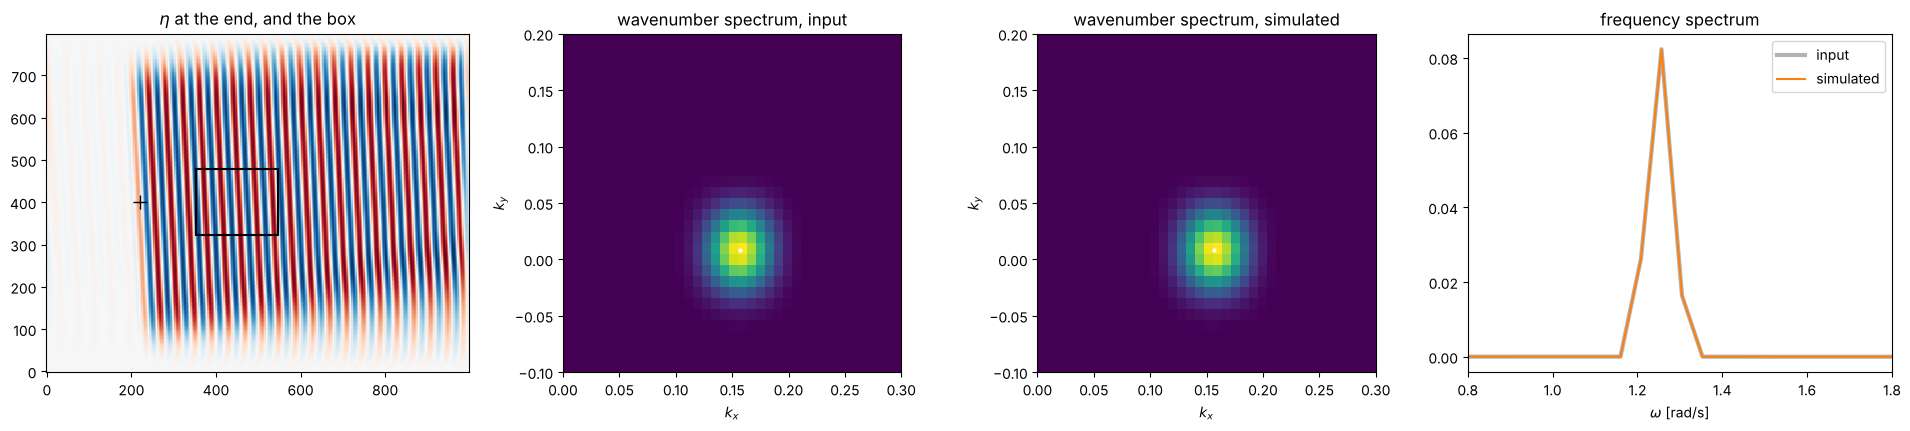

variance: simulated 0.1250, input 0.1250 m^2
relative L2 difference: wavenumber spectrum 0.002, frequency spectrum 0.001


In [5]:
k1, th1, a1 = np.array([2*np.pi/40]), np.deg2rad([3]), np.array([0.5])
F1 = wm.create_exact_unidirectional_source(X, Y, k1[0], U0, H, center, theta=th1[0], a=a1[0], **source_geometry)

t1, eta1, final1 = run(F1, T_final=250, t_record=120)
eta1_in = input_field(t1, k1, th1, a1, np.array([F1.omega]), np.zeros(1))
compare(t1, eta1, eta1_in, final1, k1, th1, klim=((0, 0.3), (-0.1, 0.2)), wlim=(0.8, 1.8))

The water behind the source stays flat, so nothing goes upstream, and the spectra match the input.

### Test 2: a directional spectrum

The spectrum is 5 wavenumbers $k \in [0.12, 0.20]$ rad/m times 5 directions $\theta \in [-24°, 24°]$, with
$$ a_j \propto \exp\left(-\frac{(k_j - 0.16)^2}{2\cdot 0.03^2}\right)\cos^4\theta_j, $$
scaled to $H_s = 4\sqrt{\sum_j a_j^2/2} \approx 1.4$ m, and random phases $\phi_j$. Each component $(k_j, \theta_j, a_j, \phi_j)$ gets its own unidirectional source along its own beam, all centred at $X_c$, and `create_spectral_source` adds them up. The slowest component needs about 80 s to reach the far side of the box, so we record from 150 s to 400 s.

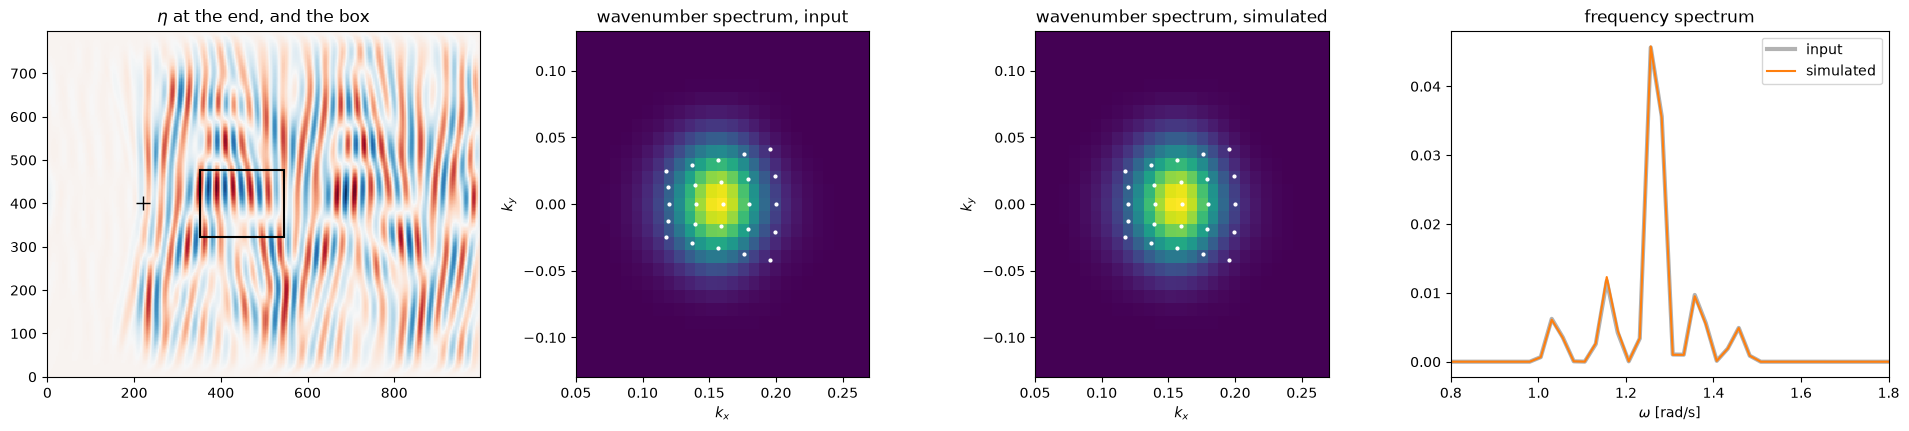

variance: simulated 0.1394, input 0.1395 m^2
relative L2 difference: wavenumber spectrum 0.006, frequency spectrum 0.013


In [7]:
KK, TT = np.meshgrid([0.12, 0.14, 0.16, 0.18, 0.20], np.deg2rad([-12, -6, 0, 6, 12]))
AA = np.exp(-0.5*((KK - 0.16)/0.03)**2)*np.cos(TT)**4
AA *= 0.5/np.sqrt(np.sum(AA**2))
k2, th2, a2 = KK.ravel(), TT.ravel(), AA.ravel()

F2 = wm.create_spectral_source(X, Y, k2, th2, a2, U0, H, center, ramp_periods=5, seed=1, **source_geometry)

t2, eta2, final2 = run(F2, T_final=400, t_record=150)
eta2_in = input_field(t2, k2, th2, a2, F2.omega, F2.phase)
compare(t2, eta2, eta2_in, final2, k2, th2, klim=((0.05, 0.27), (-0.13, 0.13)), wlim=(0.8, 1.8))

The simulated spectra lie on top of the input ones, in both wavenumber and frequency, and the variance in the box is what we asked for. The 200 m box can't resolve the single components in $\mathbf{k}$ (the white dots), but the 250 s record does separate them in frequency.